In [1]:
import pandas as pd

load_column = "SE_3_load_actual_entsoe_transparency"

demand = pd.read_csv(
    "data/time_series_60min_singleindex.csv",
    usecols=["utc_timestamp", load_column],
).rename(columns={load_column: "demand_mw"})

demand["utc_timestamp"] = pd.to_datetime(demand["utc_timestamp"], utc=True)
demand = demand.sort_values("utc_timestamp").set_index("utc_timestamp")

print("Date range:", demand.index.min(), "to", demand.index.max())
print("Missing demand values:", demand["demand_mw"].isna().sum())
print("Duplicate timestamps:", demand.index.duplicated().sum())
print(demand.head())

Date range: 2014-12-31 23:00:00+00:00 to 2020-09-30 23:00:00+00:00
Missing demand values: 80
Duplicate timestamps: 0
                           demand_mw
utc_timestamp                       
2014-12-31 23:00:00+00:00        NaN
2015-01-01 00:00:00+00:00        NaN
2015-01-01 01:00:00+00:00     9277.0
2015-01-01 02:00:00+00:00     9132.0
2015-01-01 03:00:00+00:00     9083.0


In [6]:
print("Total rows:", len(demand))
print("Missing demand readings:", demand["demand_mw"].isna().sum())
print("Duplicate timestamps:", demand.index.duplicated().sum())

Total rows: 50401
Missing demand readings: 80
Duplicate timestamps: 0


In [7]:
january = demand.loc["2019-01", "demand_mw"]

print("January rows:", len(january))
print("Missing January readings:", january.isna().sum())

January rows: 744
Missing January readings: 0


<Axes: title={'center': 'SE3 daily average electricity demand — January 2019'}, xlabel='Date (UTC)', ylabel='Demand (MW)'>

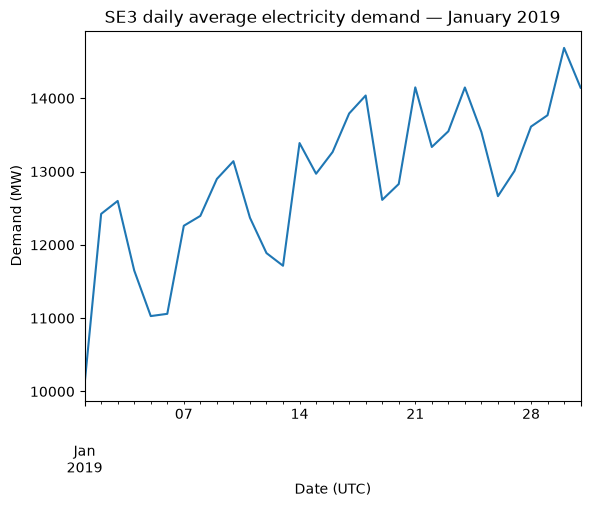

In [8]:
january.resample("D").mean().plot(
    title="SE3 daily average electricity demand — January 2019",
    xlabel="Date (UTC)",
    ylabel="Demand (MW)",
)

### Daily electricity demand in SE3 — January 2019

The chart shows how electricity demand varied from day to day in Sweden’s SE3 bidding zone. Each point is the average of the hourly demand readings for one UTC day, measured in megawatts (MW).
Average demand was highest on Jan 30 and lowest on Jan 1.

In [9]:
# Calculate daily averages using days with 24 valid hourly readings
by_day = january.resample("D")
daily = by_day.mean()[by_day.count().eq(24)]

weekday_mean = daily[daily.index.day_of_week < 5].mean()
weekend_mean = daily[daily.index.day_of_week >= 5].mean()
weekend_change = 100 * (weekend_mean / weekday_mean - 1)

print(f"Lowest daily average: {daily.min():,.0f} MW on {daily.idxmin():%d %b}")
print(f"Highest daily average: {daily.max():,.0f} MW on {daily.idxmax():%d %b}")
print(f"Peak-to-trough difference: {daily.max() - daily.min():,.0f} MW")
print(f"Weekday average: {weekday_mean:,.0f} MW")
print(f"Weekend average: {weekend_mean:,.0f} MW")
print(f"Weekend change relative to weekdays: {weekend_change:+.1f}%")

Lowest daily average: 10,103 MW on 01 Jan
Highest daily average: 14,687 MW on 30 Jan
Peak-to-trough difference: 4,584 MW
Weekday average: 13,140 MW
Weekend average: 12,101 MW
Weekend change relative to weekdays: -7.9%


### Daily electricity demand in SE3 — January 2019

Daily average demand ranged from **10,103 MW on 1 January** to
**14,687 MW on 30 January**, a peak-to-trough difference of **4,584 MW**.
The lowest-demand day was New Year’s Day, a public holiday that falls
within the Monday–Friday group.

Weekend demand averaged **12,101 MW**, compared with **13,140 MW** on
weekdays. That is **7.9% lower** over the month. This weekday–weekend
difference motivates testing a weekly forecasting baseline that uses
demand from the same hour seven days earlier. Checking additional months
would show how consistently the pattern holds.

In [10]:
demand_local = demand.tz_convert("Europe/Stockholm").copy()

demand_local.head()

,demand_mw
utc_timestamp,
2015-01-01 00:00:00+01:00,NaN
2015-01-01 01:00:00+01:00,NaN
2015-01-01 02:00:00+01:00,9277.0
2015-01-01 03:00:00+01:00,9132.0
2015-01-01 04:00:00+01:00,9083.0


In [11]:
demand_local["hour"] = demand_local.index.hour
demand_local["day_type"] = "Weekday"

demand_local.loc[
    demand_local.index.day_of_week >= 5, "day_type"
] = "Weekend"

demand_local[["hour", "day_type", "demand_mw"]].head()

,hour,day_type,demand_mw
utc_timestamp,,,
2015-01-01 00:00:00+01:00,0,Weekday,NaN
2015-01-01 01:00:00+01:00,1,Weekday,NaN
2015-01-01 02:00:00+01:00,2,Weekday,9277.0
2015-01-01 03:00:00+01:00,3,Weekday,9132.0
2015-01-01 04:00:00+01:00,4,Weekday,9083.0


In [12]:
hourly_average = (
    demand_local.groupby(["hour", "day_type"])["demand_mw"]
    .mean()
    .unstack("day_type")
)

hourly_average.head()

day_type,Weekday,Weekend
hour,,
0,8636.457333,8380.128763
1,8461.064710,8190.132107
2,8403.487333,8084.832496
3,8403.147333,8046.576923
4,8481.286000,8018.065775


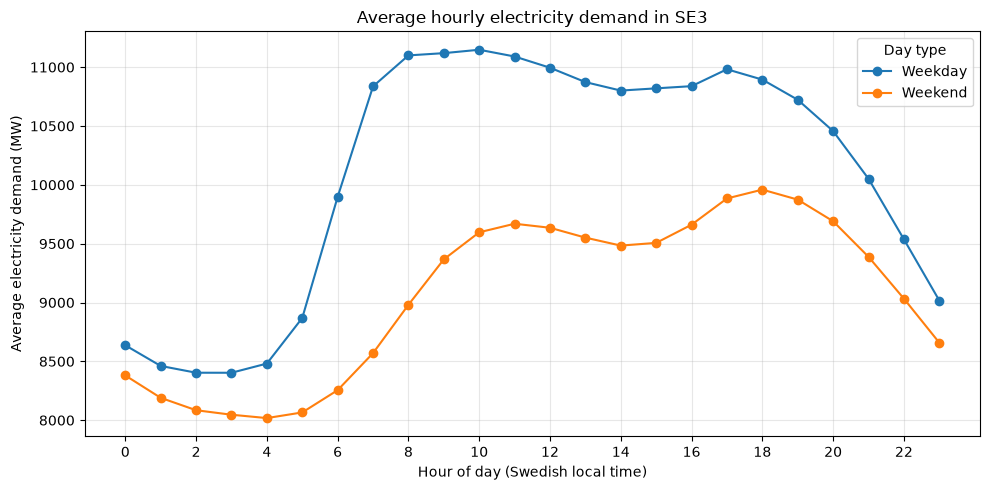

In [13]:
import matplotlib.pyplot as plt

ax = hourly_average.plot(figsize=(10, 5), marker="o")
ax.set_title("Average hourly electricity demand in SE3")
ax.set_xlabel("Hour of day (Swedish local time)")
ax.set_ylabel("Average electricity demand (MW)")
ax.set_xticks(range(0, 24, 2))
ax.legend(title="Day type")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
hourly_average.assign(
    gap_mw=(hourly_average["Weekday"] - hourly_average["Weekend"]).abs()
).sort_values("gap_mw", ascending=False).head(3).round(0)

day_type,Weekday,Weekend,gap_mw
hour,,,
7,10837.0,8570.0,2267.0
8,11100.0,8981.0,2119.0
9,11119.0,9367.0,1752.0


### Results

The plot shows average hourly electricity demand in SE3 for weekdays and
weekends, using Swedish local time. The averages include all months and
years in the dataset.

Weekday demand rises sharply between 05:00 and 08:00, while weekend demand
rises more gradually. The largest gap occurs around 07:00, when average
weekday demand is about 2,300 MW higher than weekend demand.

Both curves rise again after 14:00. To investigate whether this rise is
stronger during darker months, compare the hourly profiles for January
and June separately.

In [15]:
# Select June and November readings at 14:00 and 18:00
selected = demand_local.loc[
    demand_local.index.month.isin([6, 11])
    & demand_local["hour"].isin([14, 18])
].copy()

selected["month"] = selected.index.month.map({6: "June", 11: "November"})

# Calculate average demand at each hour
comparison = (
    selected.groupby(["month", "day_type", "hour"])["demand_mw"]
    .mean()
    .unstack("hour")
    .rename(columns={14: "14:00 (MW)", 18: "18:00 (MW)"})
)

# Calculate the change relative to 14:00
comparison["Change (MW)"] = comparison["18:00 (MW)"] - comparison["14:00 (MW)"]
comparison["Change (%)"] = (
    comparison["Change (MW)"] / comparison["14:00 (MW)"] * 100
)

display(comparison.round(2))

# Compare the percentage changes between November and June
change_by_month = comparison["Change (%)"].unstack("month")
change_by_month["November minus June (percentage points)"] = (
    change_by_month["November"] - change_by_month["June"]
)

display(change_by_month.round(2))

hour               14:00 (MW)  18:00 (MW)  Change (MW)  Change (%)
month    day_type                                                 
June     Weekday      9246.55     8854.98      -391.57       -4.23
         Weekend      7727.18     7804.10        76.92        1.00
November Weekday     12206.25    12548.09       341.84        2.80
         Weekend     10823.12    11539.10       715.98        6.62

month,June,November,November minus June (percentage points)
day_type,,,
Weekday,-4.23,2.80,7.04
Weekend,1.00,6.62,5.62


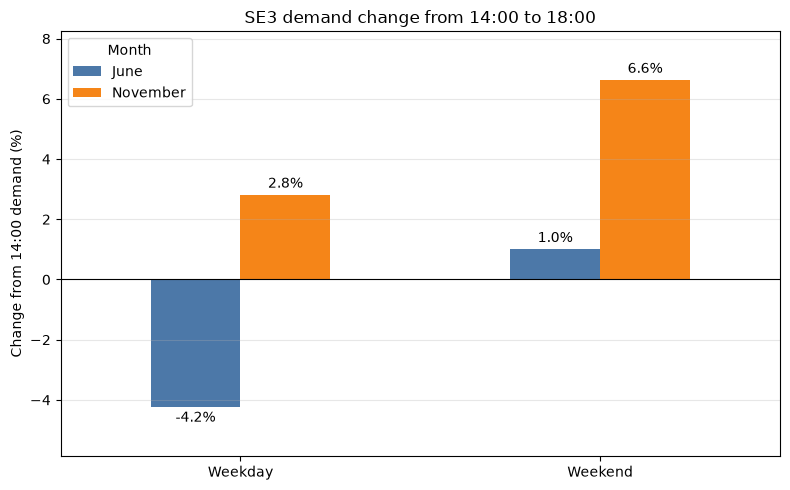

In [16]:
import matplotlib.pyplot as plt

ax = change_by_month[["June", "November"]].plot(
    kind="bar",
    figsize=(8, 5),
    color=["#4C78A8", "#F58518"],
    rot=0,
)

ax.set_title("SE3 demand change from 14:00 to 18:00")
ax.set_xlabel("")
ax.set_ylabel("Change from 14:00 demand (%)")
ax.axhline(0, color="black", linewidth=0.8)
ax.legend(title="Month")
ax.grid(axis="y", alpha=0.3)
ax.margins(y=0.15)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

### Afternoon electricity demand in SE3: June vs. November

The chart compares average electricity demand at 18:00 with average
demand at 14:00 Swedish local time. The averages use all June and
November readings available in the dataset.

- **Weekdays:** Demand fell by **4.2%** in June and rose by **2.8%** in
  November, a difference of **7.0 percentage points**.
- **Weekends:** Demand rose by **1.0%** in June and **6.6%** in November,
  a difference of **5.6 percentage points**.

November showed a stronger late-afternoon increase for both day types.
Earlier sunsets could contribute through increased lighting use. Outdoor
temperature, heating demand, and seasonal routines could also influence
the difference.